In [2]:
import numpy as np
from scipy.io import wavfile
import IPython.display as ipd
from scipy import signal as sig
from scipy.linalg import solve_toeplitz
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%config InlineBackend.figure_format = 'svg'

import Funciones as Funciones
from NNMF_GIF import NNMF_GIF
from MetricasRendimiento import MetricasRendimiento
import ray


In [96]:
with open("Señales Repositorio II Resampleadas/Listas señales/Completa U.txt", "r") as f:
    archivos = [line.strip() for line in f]
#archivos = archivos[0]



In [97]:
# Definición de parámetros
norma ='frobenius'
pre_iteraciones = 0
iteraciones     = 250
p_filtro        = 12
alfa = 0.96
p = 0.55
pre_enfasis     = True
duracion        = 5.5
guardar_proceso = False
fs_r = 8000


In [98]:
p = np.arange(0.20,2.0,0.01)
mediana_Evg1 = []
p25_Evg1     = []
p75_Evg1     = []
mediana_Evg2 = []
p25_Evg2     = []
p75_Evg2     = []

In [99]:
''' 
for p_ in p:
    evg1 = []
    evg2 = []
    for archivo in archivos:
        señales       = np.loadtxt("Señales Repositorio II Resampleadas/"+archivo+".txt", delimiter="\t")
        tiempos_      = señales[:, 0]
        señal_speech_ = señales[:, 1]
        señal_flujo_  = señales[:, 2]
        señal_dflujo_ = señales[:, 3]
        señal_area_   = señales[:, 4]
        señal_darea_  = señales[:, 5]
        to = 750
        tf = 800
        no = int(np.round(to *fs_r/1000)) 
        nf = int(np.round(tf * fs_r/1000))
        tiempos       = tiempos_[no:nf]

        señal_speech  = señal_speech_[no:nf]
        señal_flujo   = señal_flujo_[no:nf]
        señal_dflujo   = señal_dflujo_[no:nf]

        SP1 = NNMF_GIF(señal_speech,tiempos,fs_r,
                    norma=norma,
                    pre_iteraciones=pre_iteraciones,
                    iteraciones=iteraciones,
                    p_filtro=p_filtro,
                    alfa=alfa,
                    p=p_,
                    pre_enfasis=pre_enfasis,
                    duracion=duracion,
                    guardar_proceso=True)

        señal_flujo  = señal_flujo[SP1.orden_filtro_tracto-1:len(señal_flujo)-SP1.orden_filtro_tracto-1]
        señal_dflujo = señal_dflujo[SP1.orden_filtro_tracto-1:len(señal_dflujo)-SP1.orden_filtro_tracto-1]


        tiempo_flujo1,_,flujo1 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_flujo,SP1.flujo1)
        tiempo_flujo2,_,flujo2 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_flujo,SP1.flujo2)

        tiempo_dflujo1,señal_dflujo_1,dflujo1 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_dflujo,SP1.dflujo1)
        tiempo_dflujo2,señal_dflujo_2,dflujo2 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_dflujo,SP1.dflujo2)

        MR1 = MetricasRendimiento(señal_dflujo_1,Funciones.Escalar(dflujo1,señal_dflujo_1),fs_r,tiempo_dflujo1)
        MR2 = MetricasRendimiento(señal_dflujo_2,Funciones.Escalar(dflujo2,señal_dflujo_2),fs_r,tiempo_dflujo2)
        evg1.append(MR1.Error)
        evg2.append(MR2.Error)
    
    mediana_Evg1.append(np.mean(np.array(evg1)))
    p25_Evg1.append(np.percentile(np.array(evg1),25))
    p75_Evg1.append(np.percentile(np.array(evg1),75))
    mediana_Evg2.append(np.mean(np.array(evg2)))
    p25_Evg2.append(np.percentile(np.array(evg2),25))
    p75_Evg2.append(np.percentile(np.array(evg2),75))  
'''

# Inicializar Ray
ray.init(ignore_reinit_error=True)

# ==========================================================
# 🔹 Cargar TODOS los archivos una sola vez (optimización I/O)
# ==========================================================
datos = {
    archivo: np.loadtxt(f"Señales Repositorio II Resampleadas/{archivo}.txt", delimiter="\t")
    for archivo in archivos
}

# Compartir en memoria distribuida de Ray
datos_ref = ray.put(datos)

# ==========================================================
# 🔹 Función paralela
# ==========================================================
@ray.remote
def procesar_archivo(archivo, datos, p_, fs_r, norma, pre_iteraciones,
                     iteraciones, p_filtro, alfa, pre_enfasis, duracion):

    señales = datos[archivo]

    tiempos_      = señales[:, 0]
    señal_speech_ = señales[:, 1]
    señal_flujo_  = señales[:, 2]
    señal_dflujo_ = señales[:, 3]

    # Ventana temporal
    to = 750
    tf = 800
    no = int(np.round(to * fs_r / 1000)) 
    nf = int(np.round(tf * fs_r / 1000))

    tiempos       = tiempos_[no:nf]
    señal_speech  = señal_speech_[no:nf]
    señal_flujo   = señal_flujo_[no:nf]
    señal_dflujo  = señal_dflujo_[no:nf]

    # Modelo
    SP1 = NNMF_GIF(
        señal_speech, tiempos, fs_r,
        norma=norma,
        pre_iteraciones=pre_iteraciones,
        iteraciones=iteraciones,
        p_filtro=p_filtro,
        alfa=alfa,
        p=p_,
        pre_enfasis=pre_enfasis,
        duracion=duracion,
        guardar_proceso=True
    )

    SP1 = NNMF_GIF(señal_speech,tiempos,fs_r,
                norma=norma,
                pre_iteraciones=pre_iteraciones,
                iteraciones=iteraciones,
                p_filtro=p_filtro,
                alfa=alfa,
                p=p_,
                pre_enfasis=pre_enfasis,
                duracion=duracion,
                guardar_proceso=True)

    señal_flujo  = señal_flujo[SP1.orden_filtro_tracto-1:len(señal_flujo)-SP1.orden_filtro_tracto-1]
    señal_dflujo = señal_dflujo[SP1.orden_filtro_tracto-1:len(señal_dflujo)-SP1.orden_filtro_tracto-1]


    tiempo_flujo1,_,flujo1 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_flujo,SP1.flujo1)
    tiempo_flujo2,_,flujo2 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_flujo,SP1.flujo2)

    tiempo_dflujo1,señal_dflujo_1,dflujo1 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_dflujo,SP1.dflujo1)
    tiempo_dflujo2,señal_dflujo_2,dflujo2 = Funciones.Sincronizar2(SP1.tiempos_gve,señal_dflujo,SP1.dflujo2)

    MR1 = MetricasRendimiento(señal_dflujo_1,Funciones.Escalar(dflujo1,señal_dflujo_1),fs_r,tiempo_dflujo1)
    MR2 = MetricasRendimiento(señal_dflujo_2,Funciones.Escalar(dflujo2,señal_dflujo_2),fs_r,tiempo_dflujo2)

    return MR1.Error, MR2.Error


# ==========================================================
# 🔹 Loop principal paralelo
# ==========================================================
mediana_Evg1 = []
p25_Evg1 = []
p75_Evg1 = []

mediana_Evg2 = []
p25_Evg2 = []
p75_Evg2 = []

for p_ in p:

    # Lanzar tareas en paralelo
    futures = [
        procesar_archivo.remote(
            archivo,
            datos_ref,
            p_,
            fs_r,
            norma,
            pre_iteraciones,
            iteraciones,
            p_filtro,
            alfa,
            pre_enfasis,
            duracion
        )
        for archivo in archivos
    ]

    # Obtener resultados
    resultados = ray.get(futures)

    evg1 = [r[0] for r in resultados]
    evg2 = [r[1] for r in resultados]

    # Estadísticas
    mediana_Evg1.append(np.mean(evg1))
    p25_Evg1.append(np.percentile(evg1, 25))
    p75_Evg1.append(np.percentile(evg1, 75))

    mediana_Evg2.append(np.mean(evg2))
    p25_Evg2.append(np.percentile(evg2, 25))
    p75_Evg2.append(np.percentile(evg2, 75))


# ==========================================================
# 🔹 Cerrar Ray (opcional)
# ==========================================================
ray.shutdown()

2026-03-20 18:15:49,725	INFO worker.py:2004 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8265 


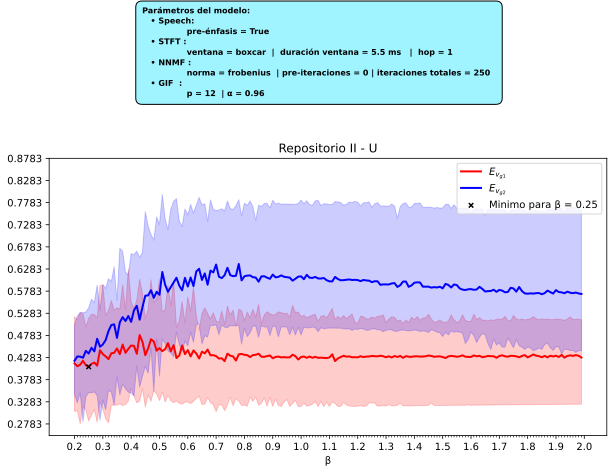

In [ ]:
fig,ax = plt.subplots(figsize=(10,5))
alpha =0.2
color1='red'
color2='blue'
ax.plot(p,mediana_Evg1,linewidth=2,color=color1,label=r"$E_{v_{g1}}$")
ax.fill_between(p,p25_Evg1, p75_Evg1,color=color1,alpha=alpha);
ax.plot(p,mediana_Evg2,linewidth=2,color=color2,label=r"$E_{v_{g2}}$")
ax.fill_between(p,p25_Evg2, p75_Evg2,color=color2,alpha=alpha);
ax.scatter(p[np.argmin(mediana_Evg1)],min(mediana_Evg1),s=20,marker='x',color='k',zorder=99,label=f'Minimo para β = {round(p[np.argmin(mediana_Evg1)],3)}')
ax.set_xticks(np.arange(p[0],p[-1]+0.1,0.1))
ax.set_xticks(np.arange(p[0],p[-1],0.01),minor=True)
ax.set_yticks(np.arange(min([min(p25_Evg1),min(p25_Evg1)]),max([max(p75_Evg1),max(p75_Evg2)])+0.1,0.05))
ax.set_xlabel("β");
ax.legend(loc='upper right')
ax.set_title("Repositorio II - U")

# ===============================  Recuadro con los parámetros del modelo ==============================================================================================
fig.text(
0.5, 1.3,  # centrado horizontalmente respecto a la figura
f"Parámetros del modelo:\n"
f"   • Speech:\n                pre-énfasis = {pre_enfasis} \n"
f"   • STFT : \n                ventana = boxcar  |  duración ventana = {duracion:.1f} ms   |  hop = 1  \n"
f"   • NNMF : \n                norma = {norma}  | pre-iteraciones = 0 | iteraciones totales = {iteraciones}  \n"
f"   • GIF  : \n                p = {p_filtro}  | α = {alfa}",
ha='center', va='top',                 # centra el recuadro
multialignment='left',                 # alinea el texto la izquierda
fontsize=8, fontweight='bold',
linespacing=1.4,
bbox=dict(facecolor=(0.624, 0.957, 1), edgecolor='black', boxstyle='round,pad=0.8')
);
#fig.savefig("Prueba beta_completa U.pdf",bbox_inches = 'tight')

In [101]:
datos = np.column_stack((
    mediana_Evg1,
    p25_Evg1,
    p75_Evg1,
    mediana_Evg2,
    p25_Evg2,
    p75_Evg2
))
np.savetxt(
    "Resultados beta - Completo U.txt",
    datos,
    delimiter="\t",
    header="mediana1\tp25_1\tp75_1\tmediana2\tp25_2\tp75_2",
    comments=""
)

np.int64(40)